# Imports 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

trips    = pd.read_parquet("../data/processed/trips.parquet")
stations = pd.read_parquet("../data/processed/stations.parquet")
status   = pd.read_parquet("../data/processed/stations_status.parquet")


# 2. Variables par station




In [3]:
# à partir des trajets qui partent de la station
departs = trips.groupby("station_id_start").agg(
    departs      = ("bike_id", "size"),
    part_matin   = ("hour", lambda h: h.between(6, 9).mean()),
    part_soir    = ("hour", lambda h: h.between(16, 19).mean()),
    part_weekend = ("is_weekend", "mean"),
    duree_med    = ("duration", "median"),
)
# trajets qui arrivent à la station
arrivees = trips.groupby("station_id_end").size().rename("arrivees")

# à partir des relevés (hors maintenance)
etat = status[~status["maintenance"]].groupby("station_id").agg(
    velos_moy = ("bikes_available_to_rent", "mean"),
    part_vide = ("bikes_available_to_rent", lambda x: (x == 0).mean()),
)

st = (stations.set_index("id")[["city_name", "lat", "lon", "dist_center_km", "is_virtual"]]
      .join(departs, how="inner").join(arrivees).join(etat))
st["arrivees"] = st["arrivees"].fillna(0)
st["solde"] = (st["arrivees"] - st["departs"]) / (st["arrivees"] + st["departs"])   # >0 : reçoit plus qu'elle n'envoie

# stations assez actives et complètes
st = st[st["departs"] >= 20].dropna()
print(len(st), "stations")


2378 stations


# 3. Préparation et ACP




In [4]:
features = ["departs", "solde", "part_matin", "part_soir", "part_weekend",
            "duree_med", "dist_center_km", "velos_moy", "part_vide"]
X = st[features].copy()
X["departs"]        = np.log(X["departs"])        # log : variables très asymétriques
X["duree_med"]      = np.log(X["duree_med"])
X["dist_center_km"] = np.log1p(X["dist_center_km"])
X["velos_moy"]      = np.log1p(X["velos_moy"])

X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=0.8)
Z = pca.fit_transform(X_scaled)
print("axes retenus :", pca.n_components_)
print("variance expliquée :", pca.explained_variance_ratio_.round(2))

pd.DataFrame(pca.components_.T, index=features,
             columns=[f"axe {i+1}" for i in range(pca.n_components_)]).round(2)


axes retenus : 5
variance expliquée : [0.23 0.22 0.16 0.11 0.09]


,axe 1,axe 2,axe 3,axe 4,axe 5
departs,0.51,-0.01,0.10,-0.08,-0.06
solde,-0.04,-0.03,0.00,0.98,-0.09
part_matin,0.15,-0.31,-0.61,-0.00,-0.04
part_soir,-0.00,0.14,0.71,-0.00,-0.22
part_weekend,-0.28,0.37,-0.03,0.09,0.74
duree_med,-0.37,0.44,-0.20,-0.15,-0.14
dist_center_km,-0.45,0.17,-0.17,-0.01,-0.59
velos_moy,0.39,0.52,-0.16,0.01,-0.13
part_vide,-0.38,-0.50,0.15,-0.11,0.06


# 4. Choix de k




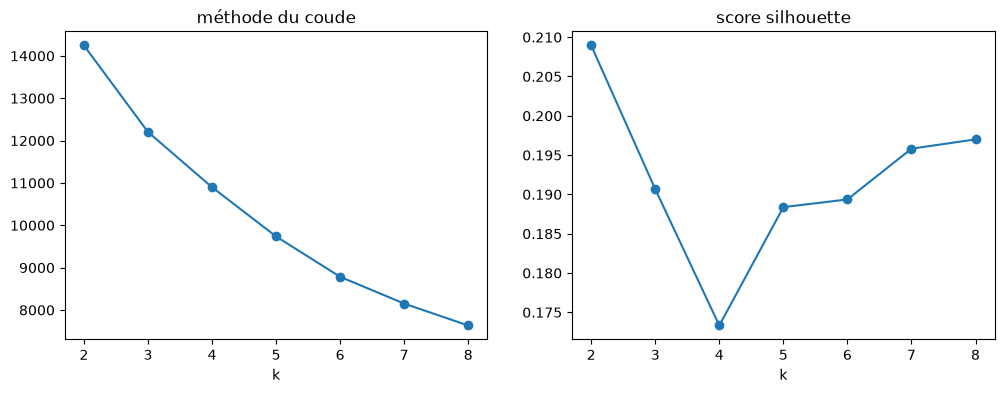

In [5]:
inertias, silhouettes = [], []
ks = range(2, 9)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(Z, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, "o-");    ax[0].set_title("méthode du coude"); ax[0].set_xlabel("k")
ax[1].plot(ks, silhouettes, "o-"); ax[1].set_title("score silhouette"); ax[1].set_xlabel("k")
plt.show()


# 5. K-means final




In [6]:
k = 4
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
st["cluster"] = kmeans.labels_
st["cluster"].value_counts().sort_index()


cluster
0    339
1    911
2    487
3    641
Name: count, dtype: int64

In [7]:
profil = st.groupby("cluster")[features].median()
profil["part_virtuelles"] = st.groupby("cluster")["is_virtual"].mean()
profil["nb_stations"] = st["cluster"].value_counts().sort_index()
profil.round(2).T


cluster,0,1,2,3
departs,83.00,451.00,229.00,98.00
solde,-0.03,-0.02,-0.01,-0.01
part_matin,0.14,0.11,0.30,0.10
part_soir,0.27,0.32,0.19,0.28
part_weekend,0.24,0.23,0.20,0.34
duree_med,780.00,720.00,660.00,1260.00
dist_center_km,2.57,1.04,1.41,3.91
velos_moy,1.72,4.73,3.83,4.67
part_vide,0.20,0.04,0.04,0.03
part_virtuelles,0.68,0.32,0.47,0.38


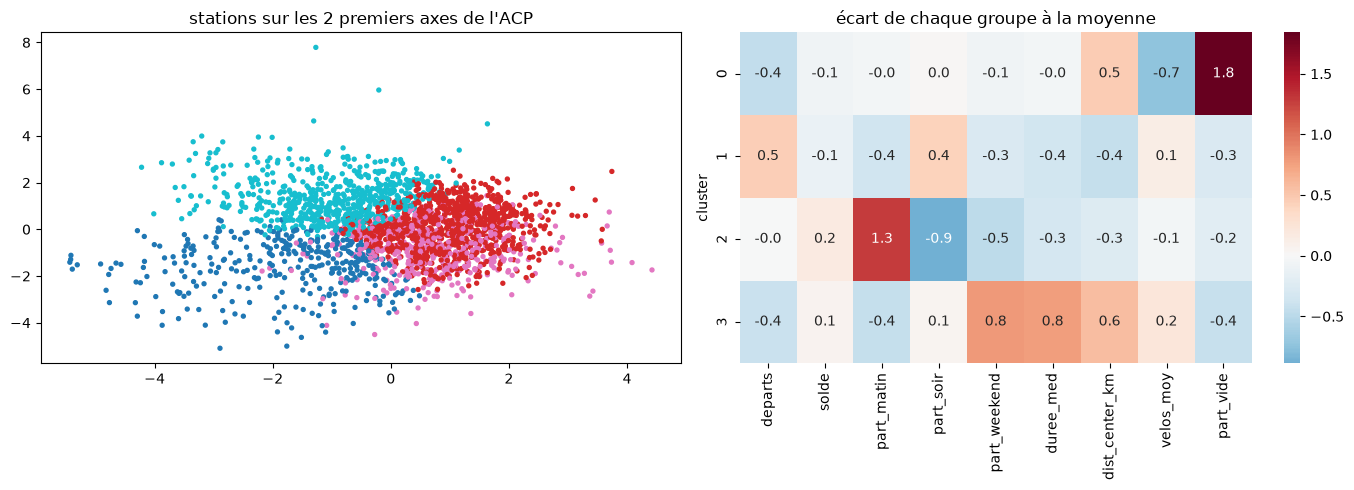

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(Z[:, 0], Z[:, 1], c=st["cluster"], cmap="tab10", s=8)
ax[0].set_title("stations sur les 2 premiers axes de l'ACP")

profil_norm = (st.groupby("cluster")[features].mean() - st[features].mean()) / st[features].std()
sns.heatmap(profil_norm, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax[1])
ax[1].set_title("écart de chaque groupe à la moyenne")
plt.tight_layout(); plt.show()
